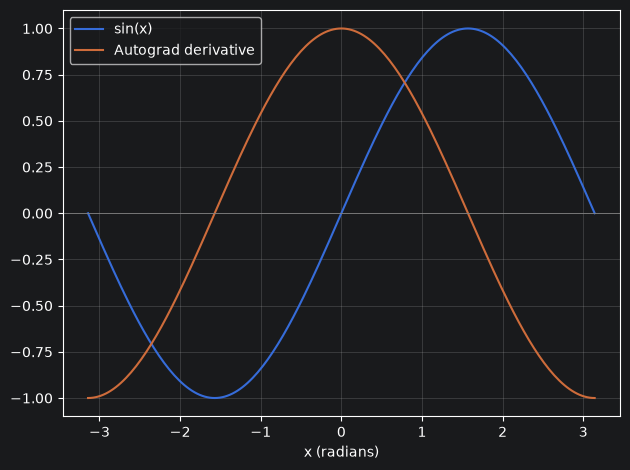

In [1]:
import torch
import matplotlib.pyplot as plt

x = torch.linspace(
    -torch.pi, torch.pi, steps=201,
    dtype=torch.float64, device="cpu",
    requires_grad=True,
)

y = torch.sin(x)
y.sum().backward()
dy = x.grad

x_plot = x.detach().numpy()

plt.plot(x_plot, y.detach().numpy(), label="sin(x)")
plt.plot(x_plot, dy.numpy(), label="Autograd derivative")
plt.axhline(0, color="gray", linewidth=0.6)
plt.xlabel("x (radians)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [2]:
import torch

x = torch.ones(5)
y = torch.zeros(3)

w = torch.randn(5, 3, requires_grad=True)
b = torch.randn(3, requires_grad=True)

z = torch.matmul(x, w) + b

loss = torch.nn.functional.binary_cross_entropy_with_logits(z, y)

print("z:", z)
print("loss:", loss)
print("z.grad_fn:", z.grad_fn)
print("loss.grad_fn:", loss.grad_fn)

loss.backward()

print("w.grad:", w.grad)
print("b.grad:", b.grad)

z: tensor([ 2.0644, -6.4656, -1.1533], grad_fn=<AddBackward0>)
loss: tensor(0.8199, grad_fn=<BinaryCrossEntropyWithLogitsBackward0>)
z.grad_fn: <AddBackward0 object at 0x000002281A3E0430>
loss.grad_fn: <BinaryCrossEntropyWithLogitsBackward0 object at 0x000002281A3E0130>
w.grad: tensor([[0.2958, 0.0005, 0.0800],
        [0.2958, 0.0005, 0.0800],
        [0.2958, 0.0005, 0.0800],
        [0.2958, 0.0005, 0.0800],
        [0.2958, 0.0005, 0.0800]])
b.grad: tensor([0.2958, 0.0005, 0.0800])
